# Problem 2: RANSAC

All of your code goes in `P2_ransac.py`. It uses `compute_homography` from `P1_extrinsics.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt


from P1_extrinsics import checkerboard_points, compute_homography, pose_from_homography
from P2_ransac import homography_residuals ,ransac_num_iterations ,ransac_homography

os.makedirs("plots", exist_ok=True)

K = np.array([[471.14628085, -4.94771211, 295.13159043],
              [0., 436.71106326, 240.96582594],
              [0., 0., 1.]])
W = checkerboard_points(9, 7, 0.0205)
uv = np.load("data/corners.npz")["uv"]
R_clean, t_clean = pose_from_homography(K, compute_homography(W, uv))

def rotation_angle_deg(Ra, Rb):
    return np.degrees(np.arccos(np.clip((np.trace(Ra.T @ Rb) - 1) / 2, -1, 1)))

## Corrupted Correspondences
30% of the detected corners are replaced by random pixels, as if the detector had matched them to the wrong points.

In [5]:
rng = np.random.default_rng(274)
N = len(uv)
outliers = rng.choice(N, int(round(0.3 * N)), replace=False)
uv_bad = uv.copy()
uv_bad[outliers] = rng.uniform([0, 0], [640, 480], (len(outliers), 2))
is_inlier = np.ones(N, dtype=bool)
is_inlier[outliers] = False

R_ls, t_ls = pose_from_homography(K, compute_homography(W, uv_bad))
print("least squares on all points: rotation error %.2f deg, translation error %.4f m"
      % (rotation_angle_deg(R_ls, R_clean), np.linalg.norm(t_ls - t_clean)))

least squares on all points: rotation error 93.96 deg, translation error 0.1170 m


## RANSAC

iterations for p = 0.99, w = 0.7, s = 4: 17
inliers found: 44 of 63, labels correct: 63 of 63
RANSAC: rotation error 0.273 deg, translation error 0.00021 m


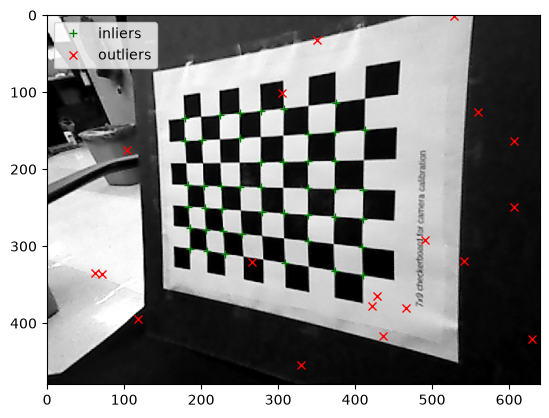

In [46]:
num_iters = ransac_num_iterations(0.99, 0.7, 4)
print("iterations for p = 0.99, w = 0.7, s = 4:", num_iters)

H, inliers = ransac_homography(W, uv_bad, num_iters=100, threshold=3.0, rng=np.random.default_rng(0))
R_r, t_r = pose_from_homography(K, H)
print("inliers found: %d of %d, labels correct: %d of %d" % (inliers.sum(), N, (inliers == is_inlier).sum(), N))
print("RANSAC: rotation error %.3f deg, translation error %.5f m"
      % (rotation_angle_deg(R_r, R_clean), np.linalg.norm(t_r - t_clean)))

image = plt.imread("data/checkerboard.png")
fig, ax = plt.subplots()
ax.imshow(image, cmap="gray")
ax.plot(uv_bad[inliers, 0], uv_bad[inliers, 1], "g+", label="inliers")
ax.plot(uv_bad[~inliers, 0], uv_bad[~inliers, 1], "rx", label="outliers")
ax.legend()
plt.savefig("plots/p2_ransac.png", bbox_inches="tight")
plt.show()

In [47]:
print("   w  | s = 4 | s = 8")
for w in [0.5, 0.7, 0.9]:
    print(f" {w:.1f}  | {ransac_num_iterations(0.99, w, 4):5d} | {ransac_num_iterations(0.99, w, 8):5d}")

   w  | s = 4 | s = 8
 0.5  |    72 |  1177
 0.7  |    17 |    78
 0.9  |     5 |     9
